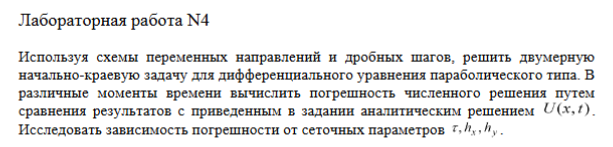

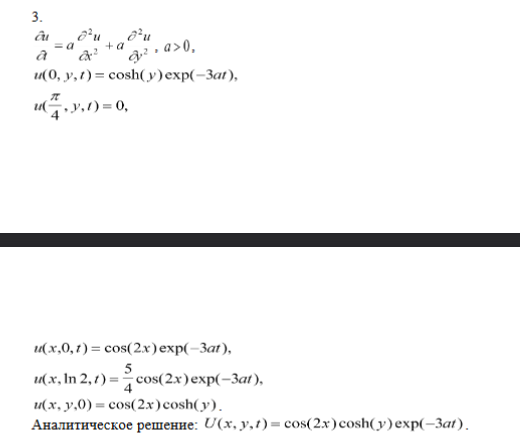

## Конечно-разностные схемы

Введём равномерную сетку

$$x_i=ih_x,\quad i=0,1,\ldots,N_x,\qquad y_j=jh_y,\quad j=0,1,\ldots,N_y,$$

$$t_n=n\tau,\qquad \Lambda_xu_{i,j}=\frac{u_{i-1,j}-2u_{i,j}+u_{i+1,j}}{h_x^2},\qquad
\Lambda_yu_{i,j}=\frac{u_{i,j-1}-2u_{i,j}+u_{i,j+1}}{h_y^2}.$$

Для схемы переменных направлений один шаг разбивается на два полушага:

$$\frac{u^{n+1/2}-u^n}{\tau/2}=a\left(\Lambda_xu^{n+1/2}+\Lambda_yu^n\right),$$

$$\frac{u^{n+1}-u^{n+1/2}}{\tau/2}=a\left(\Lambda_xu^{n+1/2}+\Lambda_yu^{n+1}\right).$$

Схема имеет порядок $O(\tau^2+h_x^2+h_y^2)$. На каждом полушаге неявным является только одно направление, поэтому вместо двумерной системы решается набор трёхдиагональных систем.

In [1]:
from math import cos, cosh, exp, log, pi, sqrt
import matplotlib.pyplot as plt

# Коэффициент уравнения, расчётная область и основная сетка.
a = 1.0
x0 = 0.0
xk = pi/4
y0 = 0.0
yk = log(2)
T = 1.0
N_x = 30
N_y = 30
tau = 0.01
times_to_show = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
surface_times = [0.0, 0.5, 1.0]

def exact_solution(x, y, t):
    return cos(2*x)*cosh(y)*exp(-3*a*t)

def phi_left(y, t):
    return cosh(y)*exp(-3*a*t)

def phi_right(y, t):
    return 0.0

def phi_bottom(x, t):
    return cos(2*x)*exp(-3*a*t)

def phi_top(x, t):
    return 5*cos(2*x)*exp(-3*a*t)/4

def make_grid(number_of_intervals, left, right):
    step = (right - left)/number_of_intervals
    return [left + index*step for index in range(number_of_intervals + 1)]

def empty_layer(N_x_local, N_y_local):
    return [[0.0]*(N_x_local + 1) for _ in range(N_y_local + 1)]

def apply_boundaries(u, x_grid, y_grid, t):
    for j, y in enumerate(y_grid):
        u[j][0] = phi_left(y, t)
        u[j][-1] = phi_right(y, t)
    for i, x in enumerate(x_grid):
        u[0][i] = phi_bottom(x, t)
        u[-1][i] = phi_top(x, t)

def initial_layer(x_grid, y_grid):
    return [
        [exact_solution(x, y, 0.0) for x in x_grid]
        for y in y_grid
    ]

### Метод прогонки

После фиксации одного из пространственных индексов каждый полушаг имеет вид

$$A_kv_{k-1}+B_kv_k+C_kv_{k+1}=D_k.$$

Все системы одного направления имеют одинаковую матрицу. Функция ниже выполняет прогонку для одной строки или одного столбца сетки.

In [2]:
def progonka(lower, diagonal, upper, right_side):
    # Коэффициенты матрицы постоянны внутри одной прогонки.
    size = len(right_side)
    P = [0.0]*size
    Q = [0.0]*size

    if size > 1:
        P[0] = -upper/diagonal
    Q[0] = right_side[0]/diagonal

    for k in range(1, size):
        denominator = diagonal + lower*P[k - 1]
        if k < size - 1:
            P[k] = -upper/denominator
        Q[k] = (right_side[k] - lower*Q[k - 1])/denominator

    solution = [0.0]*size
    solution[-1] = Q[-1]
    for k in range(size - 2, -1, -1):
        solution[k] = P[k]*solution[k + 1] + Q[k]

    return solution

### Схема переменных направлений

Обозначим $r_x=a\tau/(2h_x^2)$ и $r_y=a\tau/(2h_y^2)$. На первом полушаге прогонка выполняется вдоль $x$:

$$-r_xu_{i-1,j}^{n+1/2}+(1+2r_x)u_{i,j}^{n+1/2}-r_xu_{i+1,j}^{n+1/2}
=u_{i,j}^{n}+r_y\left(u_{i,j-1}^{n}-2u_{i,j}^{n}+u_{i,j+1}^{n}\right).$$

На втором полушаге направления меняются местами. Граничные значения берутся из условий задачи в моменты $t_{n+1/2}$ и $t_{n+1}$.

In [3]:
def alternating_direction_step(u_n, x_grid, y_grid, t_n, tau_local):
    N_x_local = len(x_grid) - 1
    N_y_local = len(y_grid) - 1
    h_x = x_grid[1] - x_grid[0]
    h_y = y_grid[1] - y_grid[0]
    r_x = a*tau_local/(2*h_x**2)
    r_y = a*tau_local/(2*h_y**2)

    # Первый полушаг: неявное направление x.
    u_half = empty_layer(N_x_local, N_y_local)
    apply_boundaries(u_half, x_grid, y_grid, t_n + tau_local/2)
    for j in range(1, N_y_local):
        right_side = [
            u_n[j][i] + r_y*(u_n[j - 1][i] - 2*u_n[j][i] + u_n[j + 1][i])
            for i in range(1, N_x_local)
        ]
        right_side[0] += r_x*u_half[j][0]
        right_side[-1] += r_x*u_half[j][-1]
        u_half[j][1:-1] = progonka(-r_x, 1 + 2*r_x, -r_x, right_side)

    # Второй полушаг: неявное направление y.
    u_n_plus_1 = empty_layer(N_x_local, N_y_local)
    apply_boundaries(u_n_plus_1, x_grid, y_grid, t_n + tau_local)
    for i in range(1, N_x_local):
        right_side = [
            u_half[j][i]
            + r_x*(u_half[j][i - 1] - 2*u_half[j][i] + u_half[j][i + 1])
            for j in range(1, N_y_local)
        ]
        right_side[0] += r_y*u_n_plus_1[0][i]
        right_side[-1] += r_y*u_n_plus_1[-1][i]
        column = progonka(-r_y, 1 + 2*r_y, -r_y, right_side)
        for j in range(1, N_y_local):
            u_n_plus_1[j][i] = column[j - 1]

    return u_n_plus_1

### Схема дробных шагов

В схеме дробных шагов каждый пространственный оператор действует на отдельном этапе:

$$\frac{u^{n+1/2}-u^n}{\tau}=a\Lambda_xu^{n+1/2},\qquad
\frac{u^{n+1}-u^{n+1/2}}{\tau}=a\Lambda_yu^{n+1}.$$

Её порядок равен $O(\tau+h_x^2+h_y^2)$. Обе схемы безусловно устойчивы, поэтому шаг по времени выбирается из требований к точности.

In [4]:
def fractional_step(u_n, x_grid, y_grid, t_n, tau_local):
    N_x_local = len(x_grid) - 1
    N_y_local = len(y_grid) - 1
    h_x = x_grid[1] - x_grid[0]
    h_y = y_grid[1] - y_grid[0]
    r_x = a*tau_local/h_x**2
    r_y = a*tau_local/h_y**2
    t_n_plus_1 = t_n + tau_local

    # Первый дробный шаг: неявное направление x.
    u_half = empty_layer(N_x_local, N_y_local)
    apply_boundaries(u_half, x_grid, y_grid, t_n_plus_1)
    for j in range(1, N_y_local):
        right_side = u_n[j][1:-1].copy()
        right_side[0] += r_x*u_half[j][0]
        right_side[-1] += r_x*u_half[j][-1]
        u_half[j][1:-1] = progonka(-r_x, 1 + 2*r_x, -r_x, right_side)

    # Второй дробный шаг: неявное направление y.
    u_n_plus_1 = empty_layer(N_x_local, N_y_local)
    apply_boundaries(u_n_plus_1, x_grid, y_grid, t_n_plus_1)
    for i in range(1, N_x_local):
        right_side = [u_half[j][i] for j in range(1, N_y_local)]
        right_side[0] += r_y*u_n_plus_1[0][i]
        right_side[-1] += r_y*u_n_plus_1[-1][i]
        column = progonka(-r_y, 1 + 2*r_y, -r_y, right_side)
        for j in range(1, N_y_local):
            u_n_plus_1[j][i] = column[j - 1]

    return u_n_plus_1

### Расчёт временных слоёв

Для сравнения с аналитическим решением сохраняются слои $t=0,0.2,\ldots,1$. Если $T/\tau$ не является целым, шаг немного корректируется так, чтобы последний слой точно соответствовал $T$.

In [5]:
def solve(method, N_x_local, N_y_local, tau_local,
          final_time=T, times_to_save=None):
    x_grid = make_grid(N_x_local, x0, xk)
    y_grid = make_grid(N_y_local, y0, yk)
    number_of_steps = round(final_time/tau_local)
    tau_actual = final_time/number_of_steps
    u_n = initial_layer(x_grid, y_grid)

    if times_to_save is None:
        times_to_save = [0.0, final_time]
    steps_to_save = {
        round(time/tau_actual): time for time in times_to_save
    }
    saved_layers = {0.0: [row.copy() for row in u_n]}
    step_function = (
        alternating_direction_step if method == 'alternating' else fractional_step
    )

    for n in range(number_of_steps):
        t_n = n*tau_actual
        u_n = step_function(u_n, x_grid, y_grid, t_n, tau_actual)
        if n + 1 in steps_to_save:
            time = steps_to_save[n + 1]
            saved_layers[time] = [row.copy() for row in u_n]

    return x_grid, y_grid, saved_layers, tau_actual

def error_norms(u, x_grid, y_grid, t):
    squared_error_sum = 0.0
    max_error = 0.0
    number_of_nodes = len(x_grid)*len(y_grid)

    for j, y in enumerate(y_grid):
        for i, x in enumerate(x_grid):
            error = abs(u[j][i] - exact_solution(x, y, t))
            max_error = max(max_error, error)
            squared_error_sum += error**2

    return max_error, sqrt(squared_error_sum/number_of_nodes)

## Сравнение методов

В таблице приведены максимальная и среднеквадратичная нормы погрешности на сохранённых временных слоях.

In [6]:
methods = {
    'Переменные направления': 'alternating',
    'Дробные шаги': 'fractional',
}

results = {}
print(f'h_x = {(xk - x0)/N_x:.5f}, h_y = {(yk - y0)/N_y:.5f}, tau = {tau:.5f}')
print(f'{"Метод":24} {"t":>5} {"||e||_inf":>14} {"||e||_rms":>14}')

for method_name, method in methods.items():
    x_grid, y_grid, layers, tau_actual = solve(
        method, N_x, N_y, tau,
        times_to_save=sorted(set(times_to_show + surface_times))
    )
    results[method_name] = layers
    for time in times_to_show:
        max_norm, rms_norm = error_norms(layers[time], x_grid, y_grid, time)
        print(f'{method_name:24} {time:5.1f} {max_norm:14.6e} {rms_norm:14.6e}')

h_x = 0.02618, h_y = 0.02310, tau = 0.01000
Метод                        t      ||e||_inf      ||e||_rms
Переменные направления     0.0   0.000000e+00   0.000000e+00
Переменные направления     0.2   1.040549e-04   3.322662e-05
Переменные направления     0.4   5.715779e-05   1.824253e-05
Переменные направления     0.6   3.136899e-05   1.001172e-05
Переменные направления     0.8   1.721567e-05   5.494550e-06
Переменные направления     1.0   9.448158e-06   3.015473e-06
Дробные шаги               0.0   0.000000e+00   0.000000e+00
Дробные шаги               0.2   5.302363e-03   2.216027e-03
Дробные шаги               0.4   2.910455e-03   1.217830e-03
Дробные шаги               0.6   1.597292e-03   6.683614e-04
Дробные шаги               0.8   8.766124e-04   3.668045e-04
Дробные шаги               1.0   4.810951e-04   2.013066e-04


## Численное и аналитическое решения

На каждом трёхмерном графике совмещены поверхности при $t=0$, $t=0.5$ и $t=1$.

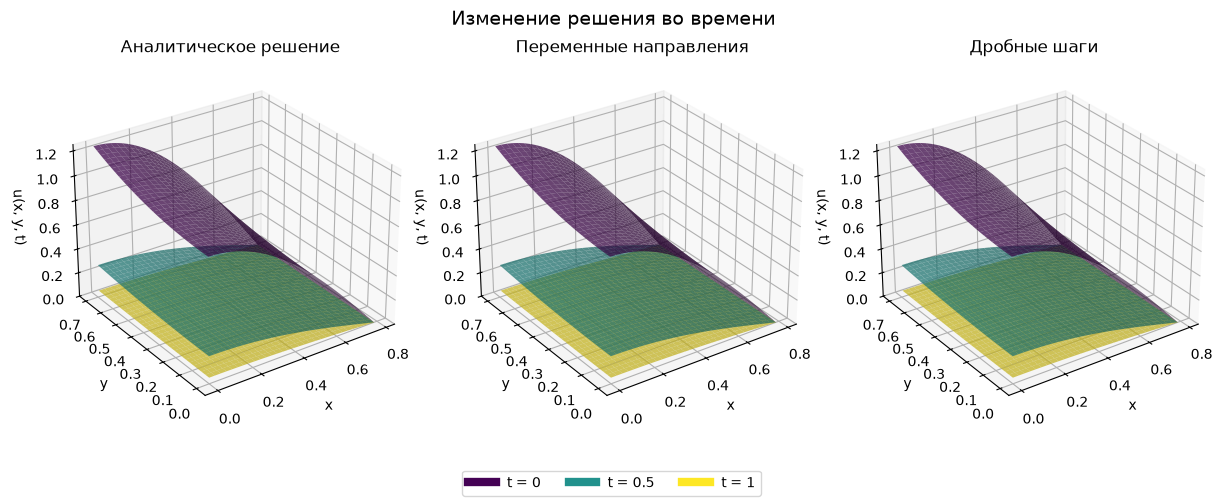

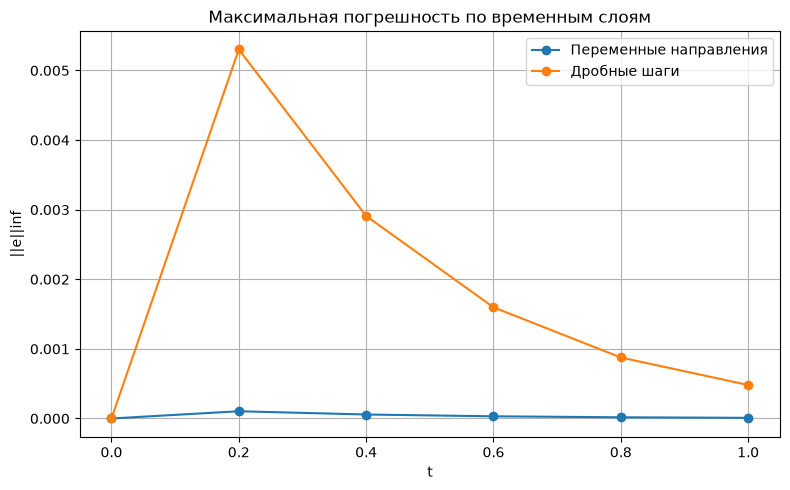

In [7]:
# NumPy используется только для подготовки координат 3D-графиков.
import numpy as np

# В каждом кубике совмещаются три временных слоя.
x_mesh, y_mesh = np.meshgrid(x_grid, y_grid)
surface_colors = ['#440154', '#21918c', '#fde725']
surface_data = {
    'Аналитическое решение': {
        time: [
            [exact_solution(x, y, time) for x in x_grid]
            for y in y_grid
        ]
        for time in surface_times
    },
}
for method_name in methods:
    surface_data[method_name] = {
        time: results[method_name][time] for time in surface_times
    }

z_min = min(
    min(min(row) for row in layers[time])
    for layers in surface_data.values()
    for time in surface_times
)
z_max = max(
    max(max(row) for row in layers[time])
    for layers in surface_data.values()
    for time in surface_times
)

figure = plt.figure(figsize=(15, 5))
for plot_number, (title, layers) in enumerate(surface_data.items(), start=1):
    axis = figure.add_subplot(1, 3, plot_number, projection='3d')
    for time, color in zip(surface_times, surface_colors):
        axis.plot_surface(
            x_mesh, y_mesh, np.array(layers[time]),
            color=color, alpha=0.72, edgecolor='none'
        )
    axis.set_title(title)
    axis.set_xlabel('x')
    axis.set_ylabel('y')
    axis.set_zlabel('u(x, y, t)')
    axis.set_zlim(z_min, z_max)
    axis.view_init(elev=28, azim=-125)

legend_elements = [
    plt.Line2D([0], [0], color=color, linewidth=6, label=f't = {time:g}')
    for time, color in zip(surface_times, surface_colors)
]
figure.legend(handles=legend_elements, loc='lower center', ncol=3)
figure.suptitle('Изменение решения во времени', fontsize=14)
figure.subplots_adjust(top=0.88, bottom=0.16, wspace=0.12)
plt.show()

figure, axis = plt.subplots(figsize=(8, 5))
for method_name in methods:
    max_errors = [
        error_norms(results[method_name][time], x_grid, y_grid, time)[0]
        for time in times_to_show
    ]
    axis.plot(times_to_show, max_errors, 'o-', label=method_name)

axis.set_title('Максимальная погрешность по временным слоям')
axis.set_xlabel('t')
axis.set_ylabel('||e||inf')
axis.grid(True)
axis.legend()
figure.tight_layout()
plt.show()

## Зависимость погрешности от параметров сетки

Сначала изменяется $\tau$ при фиксированной пространственной сетке. Затем отдельно сгущается сетка по $x$ и по $y$. Для пространственного исследования берётся малый шаг по времени, чтобы временная погрешность меньше влияла на результат.

In [8]:
def final_max_error(method, N_x_local, N_y_local,
                    tau_local, final_time):
    x_local, y_local, layers, _ = solve(
        method, N_x_local, N_y_local, tau_local, final_time
    )
    return error_norms(layers[final_time], x_local, y_local, final_time)[0]

# Зависимость от шага по времени.
time_steps = [0.04, 0.02, 0.01, 0.005]
time_errors = {method_name: [] for method_name in methods}
for method_name, method in methods.items():
    for time_step in time_steps:
        time_errors[method_name].append(
            final_max_error(method, 40, 40, time_step, 0.5)
        )

# Зависимость от пространственных шагов.
space_sizes = [10, 20, 40]
space_final_time = 0.1
space_time_step = 0.0002
x_errors = {method_name: [] for method_name in methods}
y_errors = {method_name: [] for method_name in methods}

for method_name, method in methods.items():
    for size in space_sizes:
        x_errors[method_name].append(
            final_max_error(method, size, 40, space_time_step, space_final_time)
        )
        y_errors[method_name].append(
            final_max_error(method, 40, size, space_time_step, space_final_time)
        )

print(f'{"Параметр":10} {"Значение":>10} {"Перем. напр.":>16} {"Дробные шаги":>16}')
for index, time_step in enumerate(time_steps):
    print(
        f'{"tau":10} {time_step:10.5f} '
        f'{time_errors["Переменные направления"][index]:16.6e} '
        f'{time_errors["Дробные шаги"][index]:16.6e}'
    )
for index, size in enumerate(space_sizes):
    h_x = (xk - x0)/size
    print(
        f'{"h_x":10} {h_x:10.5f} '
        f'{x_errors["Переменные направления"][index]:16.6e} '
        f'{x_errors["Дробные шаги"][index]:16.6e}'
    )
for index, size in enumerate(space_sizes):
    h_y = (yk - y0)/size
    print(
        f'{"h_y":10} {h_y:10.5f} '
        f'{y_errors["Переменные направления"][index]:16.6e} '
        f'{y_errors["Дробные шаги"][index]:16.6e}'
    )

Параметр     Значение     Перем. напр.     Дробные шаги
tau           0.04000     9.009822e-04     6.307447e-03
tau           0.02000     1.776611e-04     3.853900e-03
tau           0.01000     4.401832e-05     2.178719e-03
tau           0.00500     1.066149e-05     1.152798e-03
h_x           0.07854     1.934045e-04     2.921978e-04
h_x           0.03927     4.890292e-05     1.692247e-04
h_x           0.01963     1.265755e-05     1.618720e-04
h_y           0.06931     2.138923e-05     1.625168e-04
h_y           0.03466     1.440224e-05     1.618859e-04
h_y           0.01733     1.265755e-05     1.618720e-04


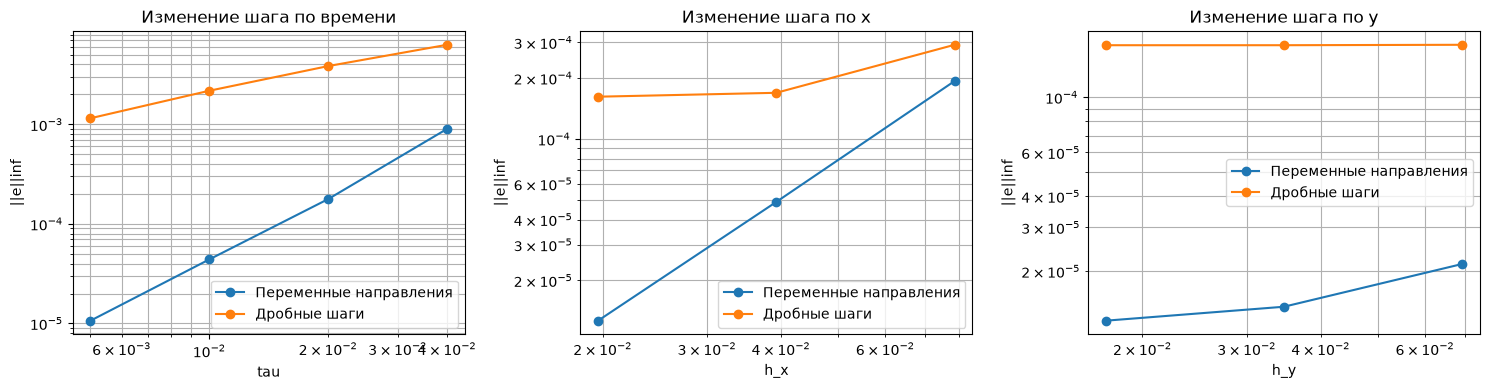

In [9]:
h_x_values = [(xk - x0)/size for size in space_sizes]
h_y_values = [(yk - y0)/size for size in space_sizes]
studies = [
    ('Изменение шага по времени', time_steps, time_errors, 'tau'),
    ('Изменение шага по x', h_x_values, x_errors, 'h_x'),
    ('Изменение шага по y', h_y_values, y_errors, 'h_y'),
]

figure = plt.figure(figsize=(15, 4))
for plot_number, (title, steps, errors, x_label) in enumerate(studies, start=1):
    axis = figure.add_subplot(1, 3, plot_number)
    for method_name in methods:
        axis.loglog(steps, errors[method_name], 'o-', label=method_name)
    axis.set_title(title)
    axis.set_xlabel(x_label)
    axis.set_ylabel('||e||inf')
    axis.grid(True, which='both')
    axis.legend()

figure.tight_layout()
plt.show()

### Вывод

Обе схемы устойчиво решают двумерную начально-краевую задачу и согласуются с аналитическим решением. При сгущении сетки погрешность уменьшается. Схема переменных направлений имеет второй порядок по времени и при одинаковых шагах оказывается точнее схемы дробных шагов, имеющей первый порядок по $\tau$. По каждой пространственной координате используются центральные разности второго порядка.